### 实验一 图像文件读取与操作、图像连通域提取

## 实验1 图像基础操作

参考官方 tutorial 教程：[Getting started with images](https://docs.opencv.org/5.0/tutorials/introduction/display_image/display_image.html)

- Read an image from file (using cv.imread)
- Display an image in an OpenCV window (using cv.imshow)
- Write an image to a file (using cv.imwrite)

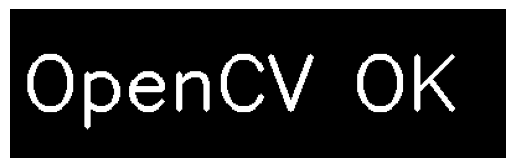

True

In [1]:
import cv2 as cv
import sys
import os
import matplotlib.pyplot as plt # jupyter 无法用imshow直接显示图片，因此用 plt 代替

os.makedirs("Exp1_figs", exist_ok=True)

img = cv.imread("Exp1_figs/hello.png")
if img is None:
    sys.exit("Could not read the image.")
# cv.imshow("Display window", img) # jupyter 使用时注释掉这一行，换成下面的 plt
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))   # 注意 BGR→RGB
plt.axis("off")
plt.show()
# k = cv.waitKey(0)
# if k == ord("s"):
#     cv.imwrite("Exp1_figs/hello.png", img)
cv.imwrite("Exp1_figs/write_img.png", img)


关于上面代码的 k 的作用，可以看 tutorial 的介绍：
> Because we want our window to be displayed until the user presses a key (otherwise the program would end far too quickly), we use the cv::waitKey function whose only parameter is just how long should it wait for a user input (measured in milliseconds). Zero means to wait forever. The return value is the key that was pressed.

## 实验2 图像基本处理

**实验要求**：能够利用OpenCV正确对图像进行翻转、旋转、缩放、灰度化与灰度反转
1. 利用 OpenCV 中的 `flip` 函数翻转图像

原图：


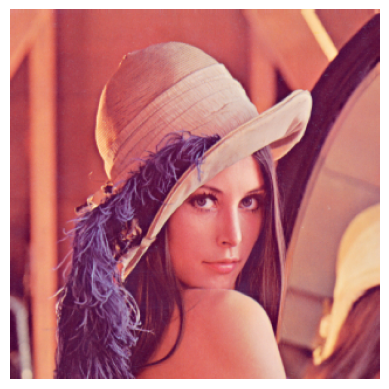

上下翻转：


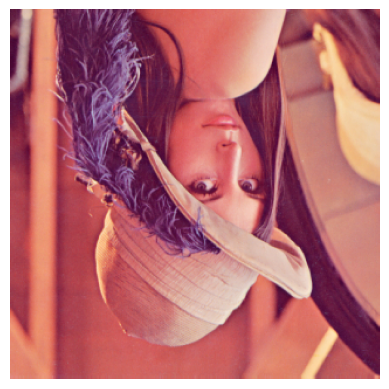

水平翻转：


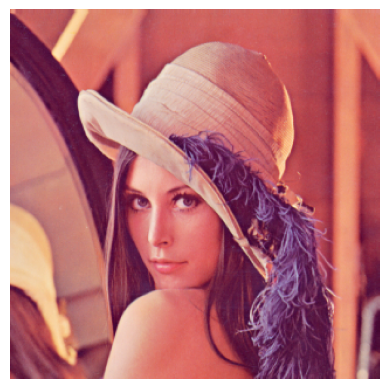

True

In [2]:
# 载入图像
img_2 = cv.imread("Exp1_figs/Lenna.jpg")
if img_2 is None:
    sys.exit("Could not read the image.")

flip_v = cv.flip(img_2, 0)  # 上下翻转
flip_h = cv.flip(img_2, 1)  # 水平翻转

print("原图：")
plt.imshow(cv.cvtColor(img_2, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

print("上下翻转：")
plt.imshow(cv.cvtColor(flip_v, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
cv.imwrite("Exp1_figs/flip_v.jpg", flip_v)

print("水平翻转：")
plt.imshow(cv.cvtColor(flip_h, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
cv.imwrite("Exp1_figs/flip_h.jpg", flip_h)


2. 利用OpenCV中`warpAffine`函数旋转图像（90°， 180 ° ，45 ° ）

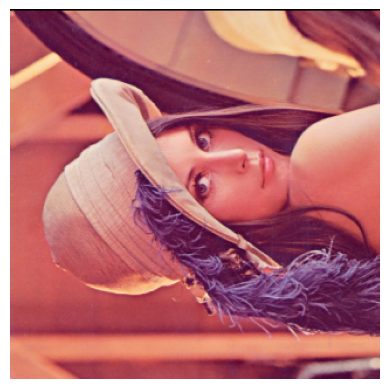

True

In [3]:
h, w = img_2.shape[:2] # 读取图像的高、宽
center = (w/2, h/2)
dsize = (w, h)
scale = 1.0

M_90 = cv.getRotationMatrix2D(center, 90, scale)
r_90 = cv.warpAffine(img_2, M_90, dsize)
plt.imshow(cv.cvtColor(r_90, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
cv.imwrite("Exp1_figs/rotate_90.jpg", r_90)


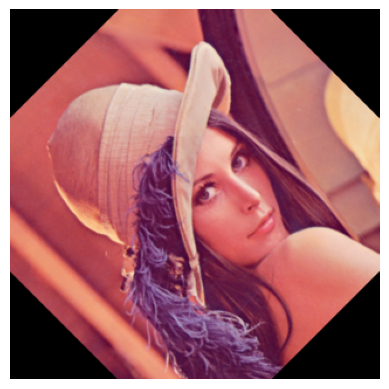

True

In [4]:
M_45 = cv.getRotationMatrix2D(center, 45, scale)
r_45 = cv.warpAffine(img_2, M_45, dsize)

plt.imshow(cv.cvtColor(r_45, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
cv.imwrite("Exp1_figs/rotate_45.jpg", r_45)


3. 利用OpenCV中`resize`函数缩放图像

由于plt会填满画布，因此用shape来判断图像尺寸是否缩放
原图： (316, 316, 3)


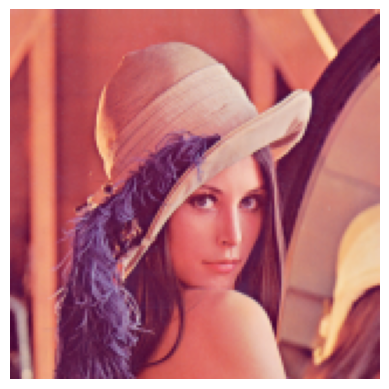

缩小： (158, 158, 3)


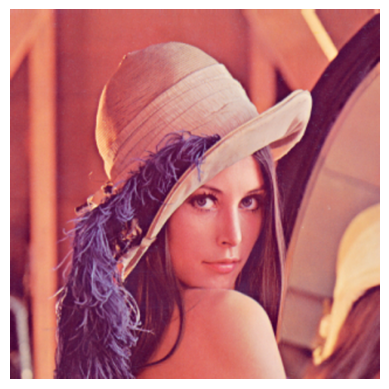

放大： (632, 632, 3)


True

In [5]:
small = cv.resize(img_2, (w//2, h//2), interpolation=cv.INTER_AREA)           # 缩小一半
big   = cv.resize(img_2, None, fx=2.0, fy=2.0, interpolation=cv.INTER_CUBIC)  # 放大两倍
print("由于plt会填满画布，因此用shape来判断图像尺寸是否缩放")
print("原图：", img_2.shape)

plt.imshow(cv.cvtColor(small, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
print("缩小：", small.shape)

plt.imshow(cv.cvtColor(big, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
print("放大：", big.shape)

cv.imwrite("Exp1_figs/resize_small.jpg", small)
cv.imwrite("Exp1_figs/resize_big.jpg", big)


4. 利用OpenCV中`cvtcolor`函数灰度化图像

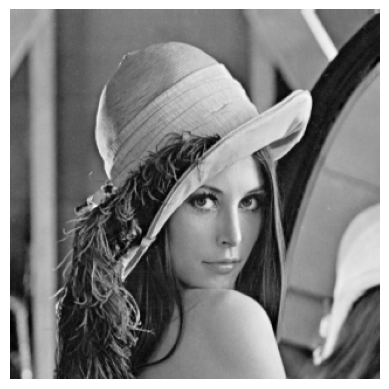

True

In [6]:
gray = cv.cvtColor(img_2, cv.COLOR_BGR2GRAY)

# plt.imshow(gray) # 直接显示会因为plt映射错误出现一片紫绿黄
plt.imshow(gray, cmap = 'gray')
plt.axis("off")
plt.show()
cv.imwrite("Exp1_figs/gray.jpg", gray)


5. 利用OpenCV或其他代码对图像进行灰度反转

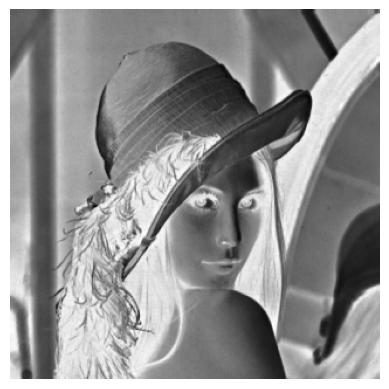

True

In [7]:
# 直接使用 255-gray 得到灰度反转
inv = 255-gray

plt.imshow(inv, cmap = 'gray')
plt.axis("off")
plt.show()
cv.imwrite("Exp1_figs/gray_inv.jpg", inv)


## 实验3 图像联通区域分析

**实验要求**：任选一张二值图像，找出二值图像所有4连通区域，并用不同颜色标记。

**实验说明**：
1. 对图像进行联通区域分析，并进行可视化。
2. 分析两种算法（两遍扫描法，种子填充法）的优缺点，包括空间复杂度、时间复杂度等

**参考文章**：[连通域原理与Python实现](https://zhuanlan.zhihu.com/p/97689424)

1. 准备二值图像

二值图尺寸 (高, 宽)： (120, 400)
前景（白色）像素数： 3965


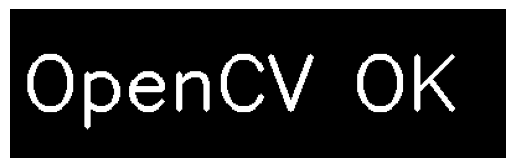

True

In [8]:
gray_bin = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
_, binary = cv.threshold(gray_bin, 127, 255, cv.THRESH_BINARY)   # 二值化

print("二值图尺寸 (高, 宽)：", binary.shape)
print("前景（白色）像素数：", int(binary.sum() / 255))

plt.imshow(binary, cmap = 'gray')
plt.axis("off")
plt.show()
cv.imwrite("Exp1_figs/binary.png", binary)


2. 算法一：种子填充法，找出所有 4 连通区域

In [9]:
# 种子填充法
h, w = binary.shape
labels_a = binary * 0     # 同尺寸全 0 标签图
count_a = 0               # 连通域个数

for y in range(h):
    for x in range(w):
        if binary[y, x] == 255 and labels_a[y, x] == 0:   # 找到一个新种子
            count_a += 1
            stack = [(x, y)]
            labels_a[y, x] = count_a
            while stack:
                cx, cy = stack.pop()
                # 只看上下左右 4 个方向
                for nx, ny in ((cx + 1, cy), (cx - 1, cy), (cx, cy + 1), (cx, cy - 1)):
                    if 0 <= nx < w and 0 <= ny < h:
                        if binary[ny, nx] == 255 and labels_a[ny, nx] == 0:
                            labels_a[ny, nx] = count_a
                            stack.append((nx, ny))

print("算法一（种子填充法）找到的 4 连通区域个数：", count_a)

算法一（种子填充法）找到的 4 连通区域个数： 8


3. 算法二：两遍扫描法，找出所有 4 连通区域

In [10]:
# 两遍扫描法
labels_b = binary * 0
parent = [0]        # parent[i] 是标号 i 的父节点
count_b = 0

def find(x):
    # 顺着父节点往上找到根
    while parent[x] != x:
        x = parent[x]
    return x

# 第一遍：扫描并打临时标号
for y in range(h):
    for x in range(w):
        if binary[y, x] == 0:
            continue
        left = labels_b[y, x - 1] if x > 0 else 0
        up   = labels_b[y - 1, x] if y > 0 else 0
        if left == 0 and up == 0:                 # 新连通域
            count_b += 1
            parent.append(count_b)
            labels_b[y, x] = count_b
        elif left != 0 and up != 0:               # 两个标号冲突，合并
            small = min(left, up)
            labels_b[y, x] = small
            parent[find(max(left, up))] = find(small)
        else:                                     # 继承有标号的那个
            labels_b[y, x] = left if left != 0 else up

# 第二遍：统一替换成根标号
root_to_new = {}
for y in range(h):
    for x in range(w):
        if labels_b[y, x] != 0:
            r = find(labels_b[y, x])
            if r not in root_to_new:
                root_to_new[r] = len(root_to_new) + 1
            labels_b[y, x] = root_to_new[r]
count_b = len(root_to_new)

print("算法二（两遍扫描法）找到的 4 连通区域个数：", count_b)
print("两个算法结果一致：", count_a == count_b)

算法二（两遍扫描法）找到的 4 连通区域个数： 8
两个算法结果一致： True


4. 用不同颜色标记连通域并可视化

原二值图（黑底白字）：


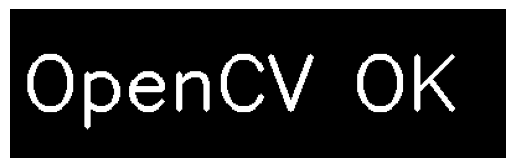

算法一（种子填充法）标记结果：


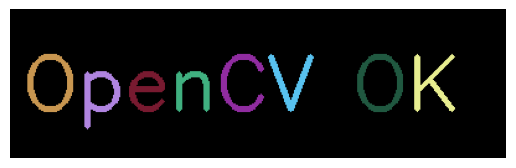

算法二（两遍扫描法）标记结果：


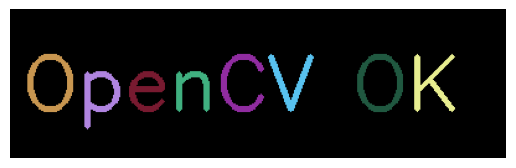

True

In [11]:
# 给每个连通域涂上不同的颜色
def colorize(labels, n):
    canvas = cv.cvtColor(labels * 0, cv.COLOR_GRAY2BGR)   # 黑底三通道图
    for i in range(1, n + 1):
        color = ((i * 80) % 256, (i * 150) % 256, (i * 200) % 256)
        canvas[labels == i] = color
    return canvas

print("原二值图（黑底白字）：")
plt.imshow(binary, cmap = 'gray')
plt.axis("off")
plt.show()

print("算法一（种子填充法）标记结果：")
color_a = colorize(labels_a, count_a)
plt.imshow(cv.cvtColor(color_a, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
cv.imwrite("Exp1_figs/labeled_seedfill.png", color_a)

print("算法二（两遍扫描法）标记结果：")
color_b = colorize(labels_b, count_b)
plt.imshow(cv.cvtColor(color_b, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
cv.imwrite("Exp1_figs/labeled_twopass.png", color_b)


5. 两种算法的对比分析

设图像共 `N` 个像素，前景像素 `M` 个，连通域个数 `K`。

| 对比项 | 种子填充法 | 两遍扫描法 |
|---|---|---|
| 时间复杂度 | `O(N + M)` | `O(N·α)`，`α` 为并查集的反阿克曼函数，近似常数 |
| 空间复杂度 | `O(N)` 标签图 + `O(M)` 栈 | `O(N)` 标签图 + `O(K)` 并查集数组 |
| 扫描遍数 | 1 遍 | 2 遍 |
| 内存访问 | 跳跃式，缓存不友好 | 顺序扫描，缓存友好 |
| 实现难度 | 简单直观 | 需要并查集，稍复杂 |

**种子填充法**：思路直观，一次扫完就标号到位。但栈深与连通域大小成正比，改成递归实现会爆栈；访问跳序，对缓存不友好。

**两遍扫描法**：顺序访问内存，不依赖栈，图像再大也不会爆栈。代价是要扫两遍，并查集逻辑更绕。

**结论**：本实验图像仅 120×400，两种算法都得到 8 个 4 连通区域，结果一致，速度无差别。图像规模变大后，两遍扫描法更稳。